In [1]:
# Import packages
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import random
import copy
from scipy import signal
import matplotlib.pylab as pl
import matplotlib.transforms as mtransforms
from scipy.optimize import curve_fit
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.dates as mdates
from scipy.stats import pearsonr
import geopandas as gpd
import os
import math
import hydroeval as he
import datetime


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.0.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "/Users/danalapides/opt/miniconda3/lib/python3.9/runpy.py", line 197, in _run_module_as_main
    return _run_code(code, main_globals, None,
  File "/Users/danalapides/opt/miniconda3/lib/python3.9/runpy.py", line 87, in _run_code
    exec(code, run_globals)
  File "/Users/danalapides/opt/miniconda3/lib/python3.9/site-packages/ipykernel_launcher.py", line 16, in <module>
    app.launch_new_instance()
  File "/Users/danalapides/opt/miniconda3/lib/python3.9/site-packages/traitlets/config/application.py", line 846, in la

AttributeError: _ARRAY_API not found


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.0.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "/Users/danalapides/opt/miniconda3/lib/python3.9/runpy.py", line 197, in _run_module_as_main
    return _run_code(code, main_globals, None,
  File "/Users/danalapides/opt/miniconda3/lib/python3.9/runpy.py", line 87, in _run_code
    exec(code, run_globals)
  File "/Users/danalapides/opt/miniconda3/lib/python3.9/site-packages/ipykernel_launcher.py", line 16, in <module>
    app.launch_new_instance()
  File "/Users/danalapides/opt/miniconda3/lib/python3.9/site-packages/traitlets/config/application.py", line 846, in la

AttributeError: _ARRAY_API not found


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.0.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "/Users/danalapides/opt/miniconda3/lib/python3.9/runpy.py", line 197, in _run_module_as_main
    return _run_code(code, main_globals, None,
  File "/Users/danalapides/opt/miniconda3/lib/python3.9/runpy.py", line 87, in _run_code
    exec(code, run_globals)
  File "/Users/danalapides/opt/miniconda3/lib/python3.9/site-packages/ipykernel_launcher.py", line 16, in <module>
    app.launch_new_instance()
  File "/Users/danalapides/opt/miniconda3/lib/python3.9/site-packages/traitlets/config/application.py", line 846, in la

AttributeError: _ARRAY_API not found


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.0.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "/Users/danalapides/opt/miniconda3/lib/python3.9/runpy.py", line 197, in _run_module_as_main
    return _run_code(code, main_globals, None,
  File "/Users/danalapides/opt/miniconda3/lib/python3.9/runpy.py", line 87, in _run_code
    exec(code, run_globals)
  File "/Users/danalapides/opt/miniconda3/lib/python3.9/site-packages/ipykernel_launcher.py", line 16, in <module>
    app.launch_new_instance()
  File "/Users/danalapides/opt/miniconda3/lib/python3.9/site-packages/traitlets/config/application.py", line 846, in la

AttributeError: _ARRAY_API not found

In [2]:
# list of sites to process
sites = ['GG1','WP1','WP2','DD','GN',]#'GN1','GN3','GN4']

In [913]:
# # process raw data files for GN1, GN3, GN4, which were installed later
# # and aren't available on the irrimax portal
# # this processing isn't done right yet

# csvfiles = [c for c in os.listdir('../Data/GN/Sentek') if c.endswith('csv')]
# alldata = {'S1':[],'S3':[],'S4':[],'S2':[]}
# for j,f1 in enumerate(csvfiles[:]):
#     print(f1, j, 'of',len(csvfiles))
#     with open('../Data/GN/Sentek/'+f1,"r",encoding='cp1252', ) as file:
#         lines = file.readlines()
#     skips2 = []
#     for i in range(len(lines)):
#         if 'DateTime' in lines[i]:
#             skips = i
#         if 'Depth' in lines[i]:
#             skips1 = i
#         if 'Name' in lines[i]:
#             skips2.append(i)
#     f = pd.read_csv('../Data/GN/Sentek/'+f1,encoding='cp1252',skiprows=skips)
#     f['DateTime'] = pd.to_datetime(f.DateTime)
#     f.set_index('DateTime',inplace=True)
#     f = f[[c for c in f.columns if 'Cook' in c]]
    
#     skipdiff = list(np.diff(skips2))
#     skips1 = skips2[skipdiff.index(max(skipdiff))]
#     dlabel = pd.read_csv('../Data/GN/Sentek/'+f1,encoding='cp1252',
#                          skiprows=skips1,nrows=len(f.columns))

#     nrow1 = 50
#     d1 = ''
#     while (len(d1)==0) & (nrow1>10):
# #         print(nrow1)
#         try:
#             d1 = pd.read_csv('../Data/GN/Sentek/'+f1,encoding='cp1252',
#                              skiprows=skips2[skipdiff.index(max(skipdiff))+1],nrows=nrow1)
#         except:
#             nrow1 -= 1
#     goodrows = []
#     for i in range(len(d1)):
#         if str(d1.Name.values[i])[0]  in ['V','A','S','T','H']:
#             goodrows.append(i)
#     dlabel1 = d1.loc[goodrows]
#     cols = f.columns
#     if dlabel[dlabel.Depth>0].Depth.min()>100:
#         divnum = 10
#     else:
#         divnum = 1
#     f.rename(columns={cols[i]:cols[i]+'_'+(dlabel.Name.values[i])+'_'+
#                       str(dlabel.Depth.values[i]/divnum) for i in range(len(cols))},
#             inplace=True)
#     f = f[[c for c in f.columns if 'A' in c.split('_')[-2]]]
#     f.rename(columns={c:c.split('_')[-2]+'('+c.split('_')[-1]+')' for c in f.columns},inplace=True)
    
    
#     key = f1.split('_')[1]
#     if 'S' not in key:
#         key = 'S2'
#     alldata[key].append(f)
    
# alldata = {k:pd.concat(alldata[k]).sort_index() for k in alldata.keys()}
# for k in alldata.keys():
#     t = alldata[k]
#     for c in t.columns:
#         t[c] = np.where(t[c]<0,np.nan,t[c])
#     if k=='S4':
#         t = t.loc['2026-02-04':]
#     alldata[k] = t
#     t.reset_index(inplace=True)
#     t.rename(columns={'DateTime':'Date Time'},inplace=True)
#     t.to_csv('../Data/GN'+k[-1]+'/afsystems'+k+'.csv',index=False)

In [518]:
### process updated groundwater data

import glob
import io

for site in ['WP1','WP2','GN','DD']:
    print(site)
    gwdata = pd.read_csv('../Data/'+site+'/gw_processed.csv')
    gwdata['Timestamps'] = pd.to_datetime(gwdata.Timestamps)
    gwdata.set_index('Timestamps',inplace=True)
    gwdata.rename(columns={'WaterLevel_mm':'DTWT'},inplace=True)
    gwdata = gwdata/1000


    # 1. Point this to the folder containing your files
    folder_path = "../Data/"+site+'/Meter/'

    # Search for all files ending in .xlsx or .xls in that folder
    file_pattern = os.path.join(folder_path, "*.xl*")
    all_files = glob.glob(file_pattern)


    all_dataframes = []

    for file in all_files:
        try:
            # Load ONLY the first sheet using the strict openpyxl engine
            df = pd.read_excel(file, sheet_name=0, engine='openpyxl',skiprows=2)

            # Filter: Only keep files where the first sheet actually has 5 or more columns
            if len(df.columns) >= 5:
                # Track which file this data came from
                df['source_file'] = os.path.basename(file)
                all_dataframes.append(df)
#                 print(f"Successfully extracted main sheet from: {os.path.basename(file)}")
            else:
                print(f"Skipped {os.path.basename(file)} (Has fewer than 5 columns)")

        except Exception as e:
            print(f"Skipping {os.path.basename(file)} due to an error: {e}")

    # 2. Combine all your cleanly parsed data tables together
    if all_dataframes:
        master_df = pd.concat(all_dataframes, ignore_index=True)
#         print("\nExtraction complete! All true data tables have been successfully combined into 'master_df'.")
#     else:
#         print("\nNo matching tables with >= 5 columns were found.")

        master_df['Timestamp'] = pd.to_datetime(master_df.Timestamp)
    master_df.set_index('Timestamp',inplace=True)
    master_df = (master_df[[' mm Water Level']]/1000).rename(columns={' mm Water Level':'DTWT'})

    gwdata = pd.concat([gwdata,master_df]).sort_index().resample('H').mean()
    gwdata.to_csv('../Data/final_processed_data/gwdata_final'+site+'.csv')
    print(gwdata.min(),gwdata.max())

WP1
DTWT    0.42575
dtype: float64 DTWT    2.54
dtype: float64
WP2
DTWT    0.5805
dtype: float64 DTWT    2.43025
dtype: float64
GN
DTWT    0.0095
dtype: float64 DTWT    1.79
dtype: float64
DD
DTWT    1.162
dtype: float64 DTWT    2.30875
dtype: float64


In [683]:
# grab SILO data for all sites so that we can compare to gages

from datetime import datetime, timedelta
import urllib.parse
import urllib.request


def download_wa_silo_rainfall(lat, lon, email, output_filename="wa_rainfall_5yrs.csv"):
    """Downloads the last 5 years of gridded rainfall-only point data from the

    SILO API for a specific location in Western Australia.

    Parameters:
        lat (float): Latitude of the target WA location (must be negative).
        lon (float): Longitude of the target WA location.
        email (str): A valid email address (required by the SILO API).
        output_filename (str): Name of the CSV file to save.
    """
    # 1. Base endpoint for gridded interpolation data drills
    base_url = "https://www.longpaddock.qld.gov.au/cgi-bin/silo/DataDrillDataset.php"

    # 2. Automatically calculate the 5-year date window
    today = pd.to_datetime('2026-10-1')
    five_years_ago = pd.to_datetime('2022-4-1')

    start_date = five_years_ago.strftime("%Y%m%d")
    finish_date = today.strftime("%Y%m%d")

    # 3. Structure parameters explicitly targeting rainfall
    # By setting format to 'rainonly', the response trims all other variables.
    params = {
        "format": "rainonly",
        "lat": f"{lat:.2f}",
        "lon": f"{lon:.2f}",
        "start": start_date,
        "finish": finish_date,
        "username": email,
        "password": "apirequest",  # Default system interaction token
    }

    # 4. Construct URL query string
    query_string = urllib.parse.urlencode(params)
    full_url = f"{base_url}?{query_string}"

    print(f"Connecting to SILO API for Western Australia coordinates...")
    print(f"Date range: {start_date} to {finish_date}")
    print(f"Requesting format: 'rainonly' from {full_url}\n")

    # 5. Execute HTTP Request and save data
    try:
        headers = {"User-Agent": "Mozilla/5.0"}
        req = urllib.request.Request(full_url, headers=headers)

        with urllib.request.urlopen(req) as response:
            data = response.read()

            with open(output_filename, "wb") as f:
                f.write(data)

        print(f"Success! WA rainfall data saved to '{output_filename}'")

    except Exception as e:
        print(f"An error occurred while fetching rainfall data: {e}")


# ==========================================
# Example Usage
# ==========================================
if __name__ == "__main__":
    # Example coordinates for Northam, Western Australia
    WA_LAT = -31.65
    WA_LON = 116.67
    USER_EMAIL = "danalapides@gmail.com"  # Replace with a valid email string

    sitelocs = {'GG1':(-31.3764, 115.7139),
               'WP1':(-31.820007, 115.932571),
               'WP2':(-31.839375, 115.956497),
               'GN':(-31.728483, 115.924080),
               'DD':(-30.869728, 115.859337),
               }
    for site in ['GG1','GN','DD','WP1','WP2']:
        WA_LAT = sitelocs[site][0]
        WA_LON = sitelocs[site][1]
        download_wa_silo_rainfall(
            lat=WA_LAT,
            lon=WA_LON,
            email=USER_EMAIL,
            output_filename='../Data/'+site+'/silo_rainfall_'+site+'.csv',
        )


Connecting to SILO API for Western Australia coordinates...
Date range: 20220401 to 20261001
Requesting format: 'rainonly' from https://www.longpaddock.qld.gov.au/cgi-bin/silo/DataDrillDataset.php?format=rainonly&lat=-31.38&lon=115.71&start=20220401&finish=20261001&username=danalapides%40gmail.com&password=apirequest

Success! WA rainfall data saved to '../Data/GG1/silo_rainfall_GG1.csv'
Connecting to SILO API for Western Australia coordinates...
Date range: 20220401 to 20261001
Requesting format: 'rainonly' from https://www.longpaddock.qld.gov.au/cgi-bin/silo/DataDrillDataset.php?format=rainonly&lat=-31.73&lon=115.92&start=20220401&finish=20261001&username=danalapides%40gmail.com&password=apirequest

Success! WA rainfall data saved to '../Data/GN/silo_rainfall_GN.csv'
Connecting to SILO API for Western Australia coordinates...
Date range: 20220401 to 20261001
Requesting format: 'rainonly' from https://www.longpaddock.qld.gov.au/cgi-bin/silo/DataDrillDataset.php?format=rainonly&lat=-30

In [39]:

calibrations = {'sentekDefault':[0.1957,0.404,0.0285],
               'group1': [0.00878, 0.952, 0.527],
               'group2': [0.21336, 0.39122, 0],
               'group3': [0.12, 0.53, 0],
               'group4': [0.1474, 0.47659, 0]}

calgroups = {'WP1':{0.3:'group4',0.5:'group4',0.7:'group4',
                   1.0:'group4',1.4:'group4',
                   1.7:'group4',2.0:'group4',
                   2.4:'group4'},
            'WP2':{0.25:'group4',0.45:'group4',
                  0.65:'group4',0.95:'group4',
                  1.25:'group4',1.55:'group4',
                   1.7:'group4',1.85:'group4',
                  2.05:'group4',2.4:'group3'},
            'GN':{0.2:'group4',0.4:'group4',
                 0.6:'group4',1.0:'group4',
                 1.5:'group4',2.0:'group4',
                 2.5:'group3',2.8:'group3',
                 3.0:'group3',3.2:'group3'},
             'GN2':{0.2:'group4',0.4:'group4',
                 0.6:'group4',1.0:'group4',
                 1.5:'group4',2.0:'group4',
                 2.5:'group3',2.8:'group3',
                 3.0:'group3',3.2:'group3'},
             'GN1':{0.2:'group4',0.4:'group4',
                 0.6:'group4',1.0:'group4',
                 1.5:'group4',2.0:'group4',
                 2.5:'group3',2.8:'group3',
                 3.0:'group3',3.2:'group3'},
             'GN3':{0.2:'group4',0.4:'group4',
                 0.6:'group4',1.0:'group4',
                 1.5:'group4',2.0:'group4',
                 2.5:'group3',2.8:'group3',
                 3.0:'group3',3.2:'group3'},
             'GN4':{0.2:'group4',0.4:'group4',
                 0.6:'group4',1.0:'group4',
                 1.5:'group4',2.0:'group4',
                 2.5:'group3',2.8:'group3',
                 3.0:'group3',3.2:'group3'},
            'GG1':{0.25:'group3',0.45:'group3',
                  0.65:'group3',0.85:'group3',
                  1.05:'group2',1.55:'group2',
                  1.95:'group2',2.55:'group3',
                  2.95:'group3',3.95:'group2',
                  4.95:'group2',5.95:'group2',
                  6.95:'group2',7.95:'group2',
                  8.55:'group2',9.05:'group2'},
            'DD':{0.25:'group1',0.45:'group1',
                 0.65:'group1',0.95:'group1',
                 1.45:'group1',1.95:'group1',
                 2.45:'group1',2.95:'group1',
                 3.95:'group1',4.95:'group2',
                 5.95:'group1',6.95:'group1',
                 7.35:'group1',7.95:'group1'}}

In [178]:
# year to start a drift correction for each sensor
driftCorrectStart = {'WP1':{
                            2.0: 2022,
                            2.4: 2023,
                           },
                     'WP2':{#1.85: 2022, # this then has a reset in mid-2024 and needs a new drift correction starting 2025
                            2.05: 2022,
                     },
                     'GG1':{0.65: 2024,
                            0.85: 2024,
                            1.55: 2024,
                            1.95: 2024,
                            1.95: 2024, # does this sensor really respond much more recently or did it get weird?
                            2.55: 2024,
                            2.95: 2024, # does this sensor really respond much more since 2024 or did it get weird?
                            3.95: 2023, # same question as above two
                            4.95: 2022,
                     },
                     'DD':{
                           4.95: 2024,
                           5.95: 2024,
                           6.95: 2024, # I don't like the data pre 2024, so I dropped it
                           7.95: 2023, # not sure I like this one
                     }
                    }
# not dropping any sensors at this point
dropsensors = {'WP2':[],#[1.85],
              'GG1':[],#[9.05],
              'DD':[],}#[7.95]}

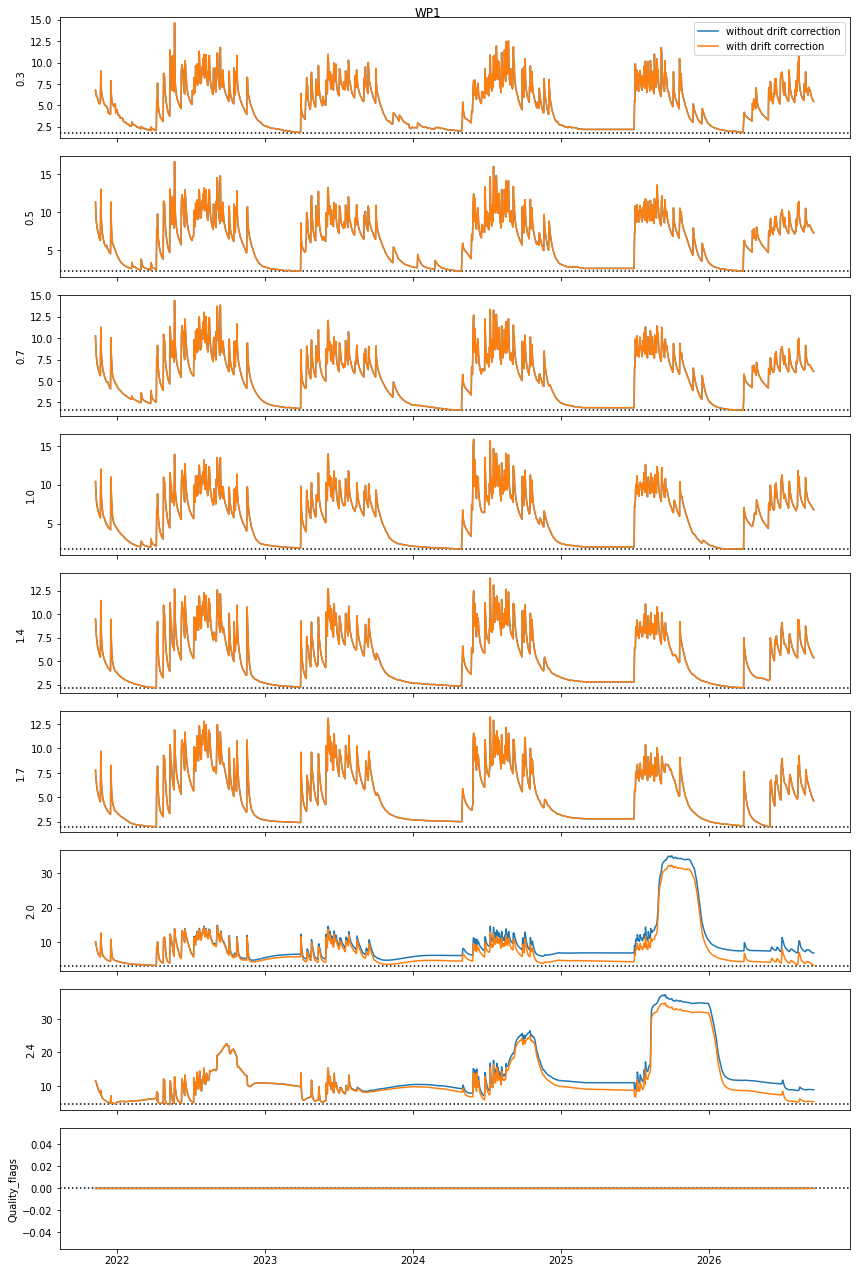

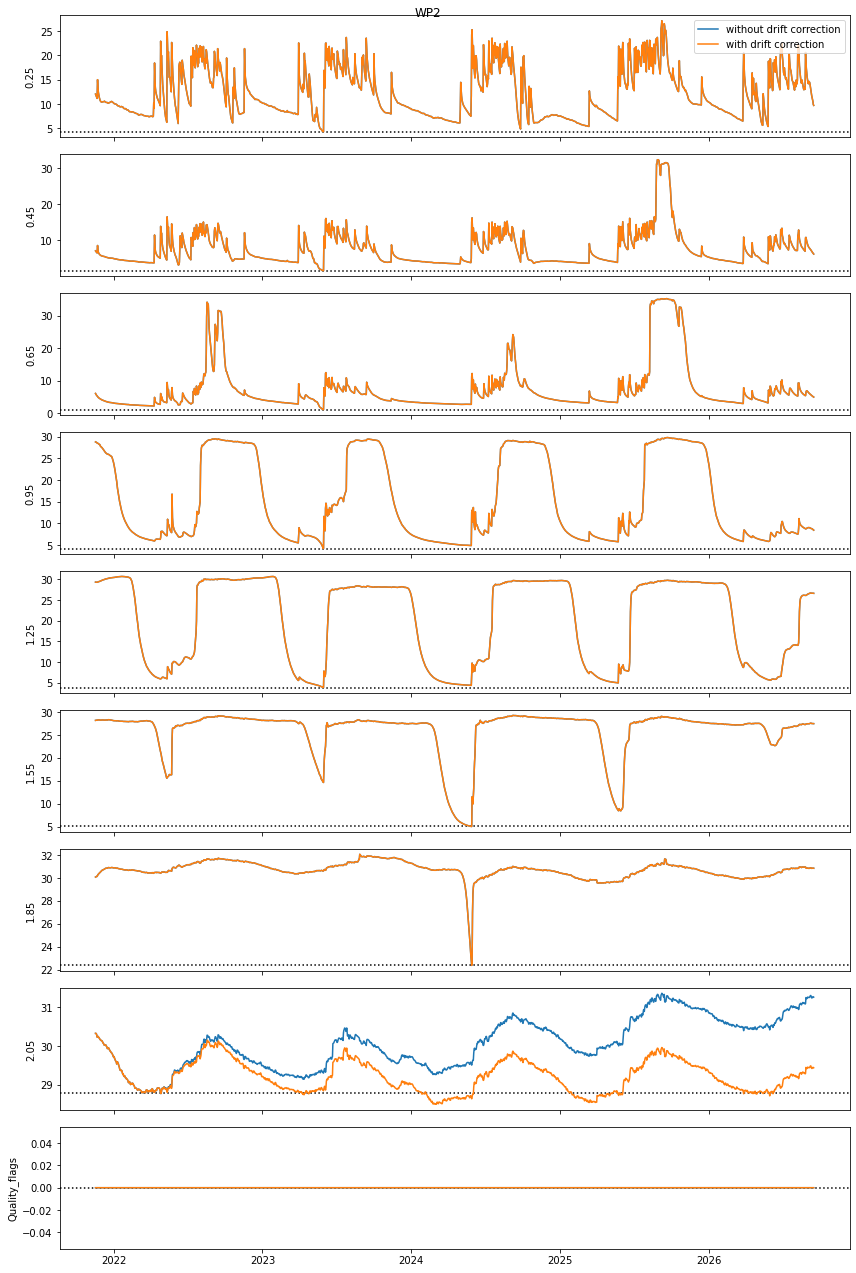

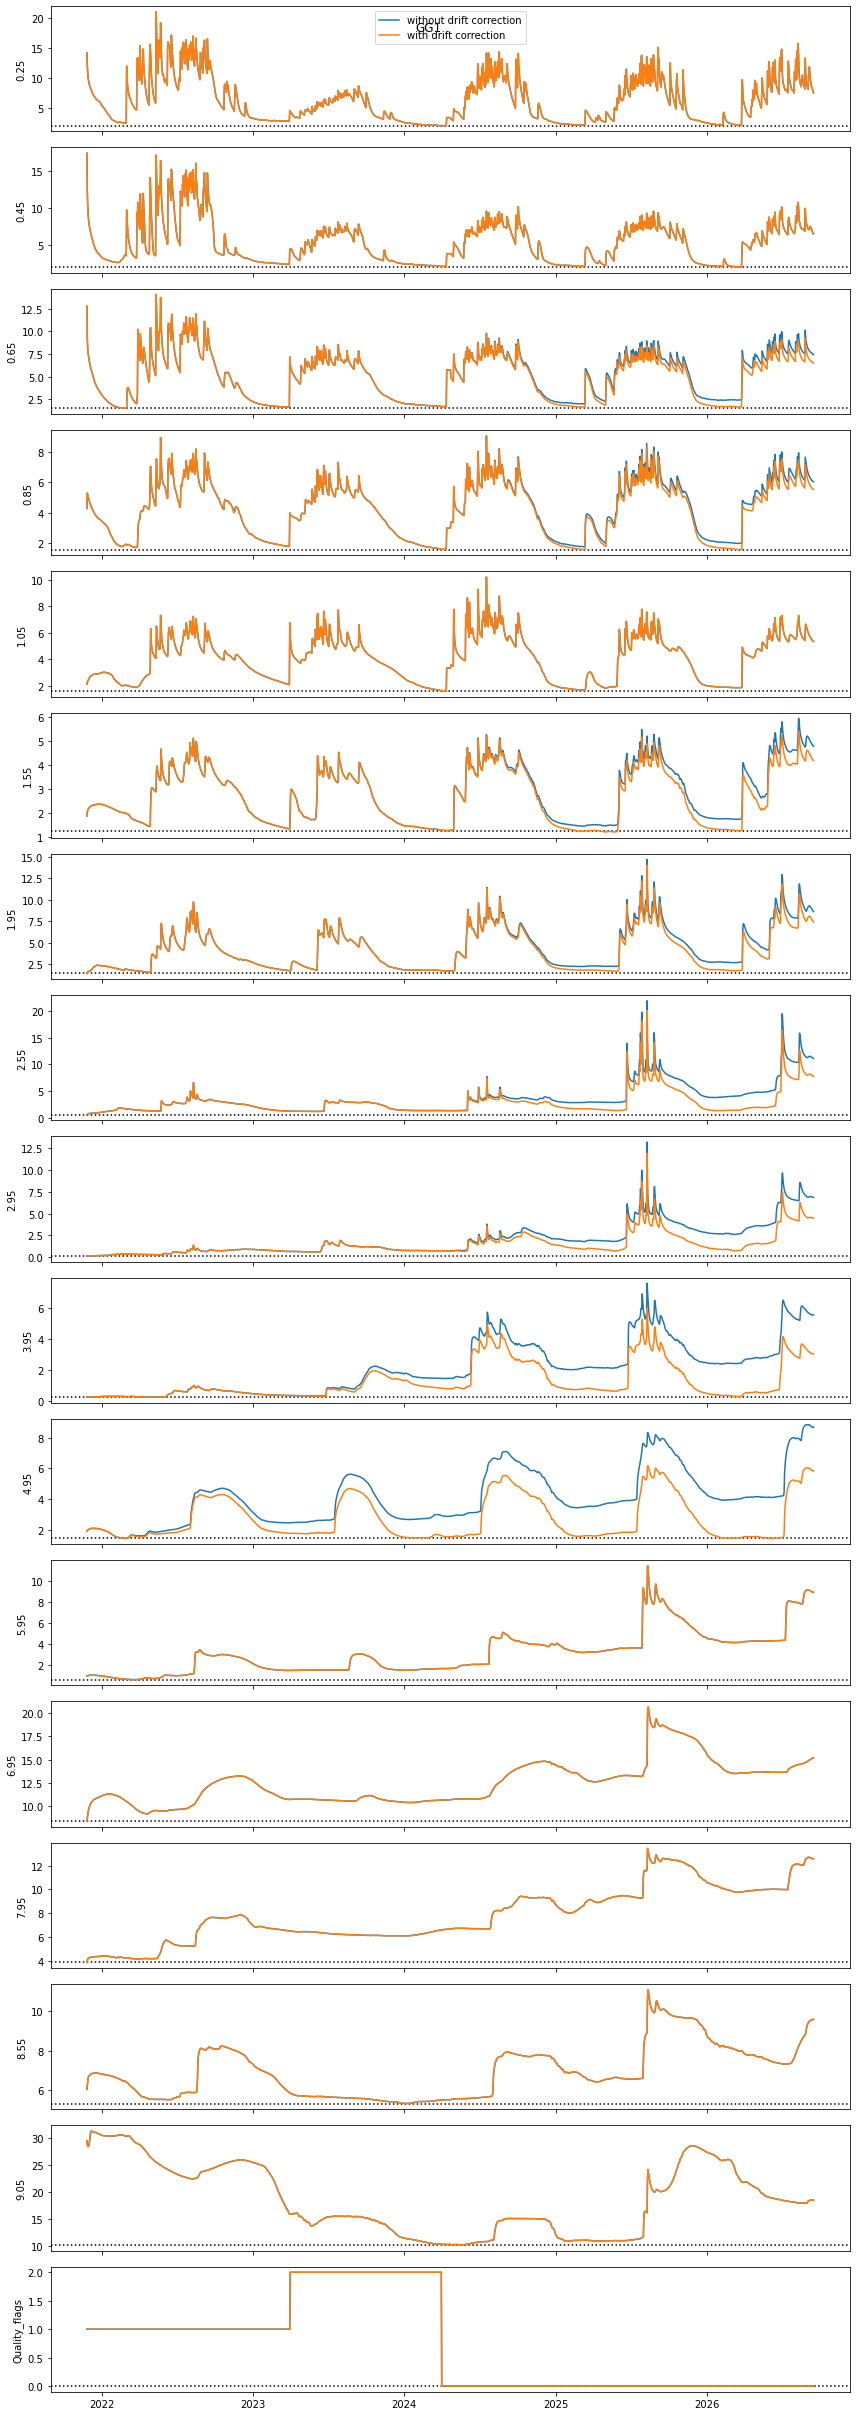

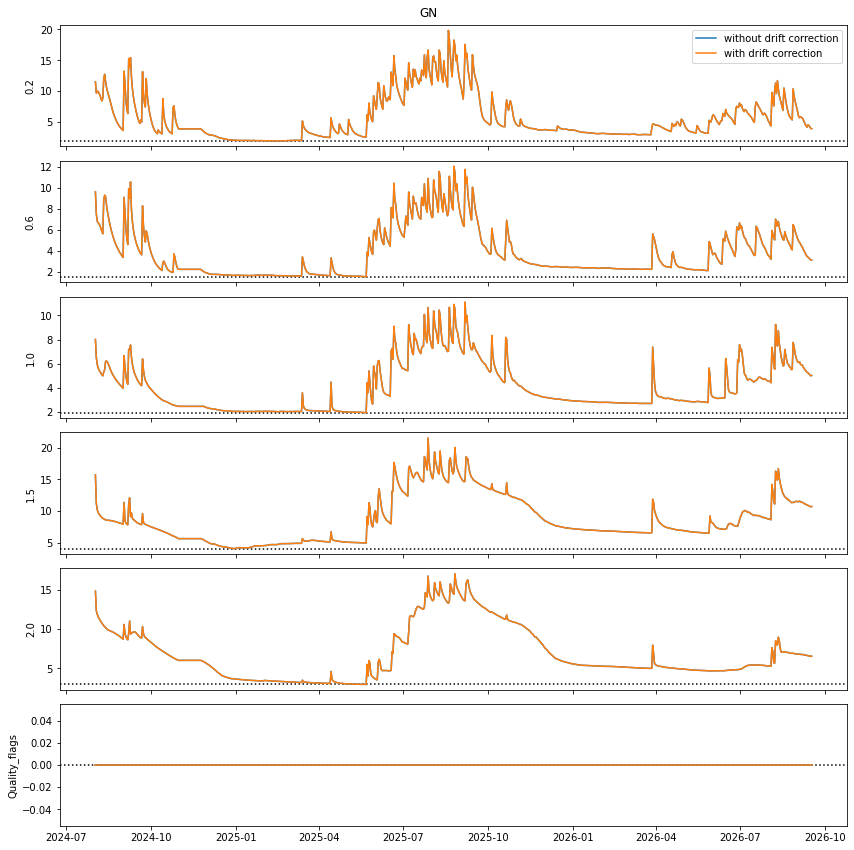

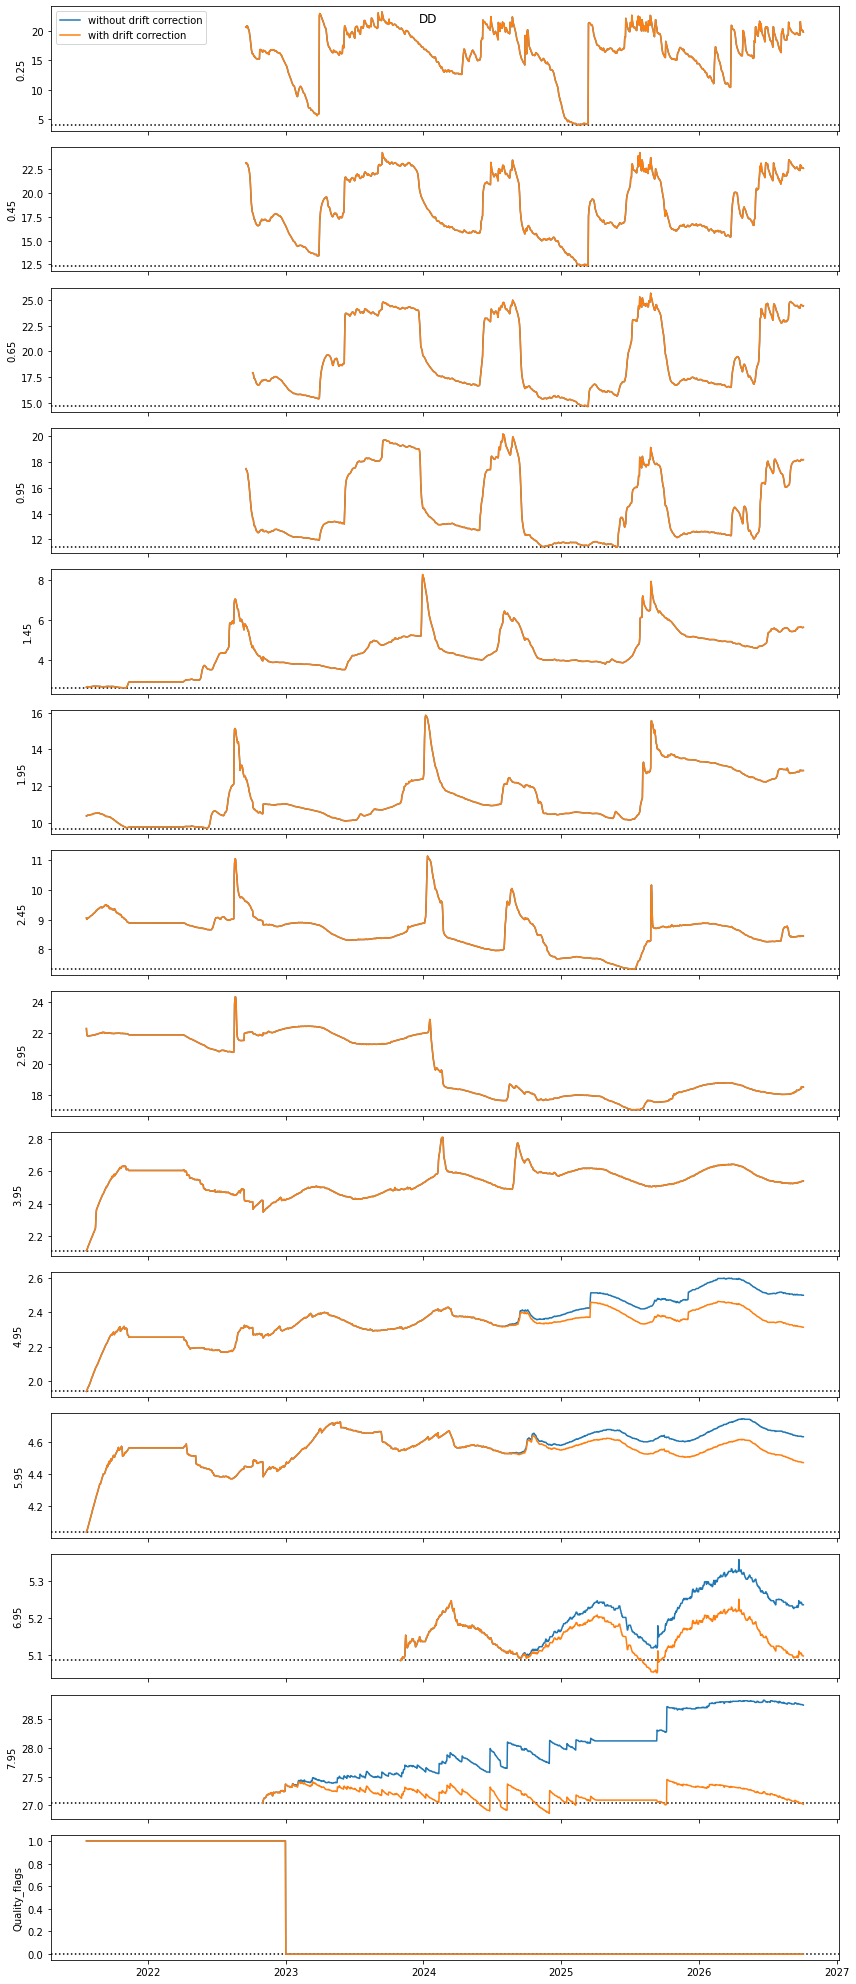

In [910]:


files = {site:[f for f in os.listdir('../Data/'+site) if f.endswith('csv') if 'afsystems' in f][0]
        for site in ['WP1','WP2','GG1','GN','DD','GN1','GN3','GN4','GN2']}

for site in list(files.keys())[:-4]:
    dataloc = '../Data/'+site+'/'
    original = pd.read_csv(dataloc+files[site])
    original['Date Time'] = pd.to_datetime(original['Date Time'])
    original.set_index('Date Time',inplace=True)
    for c in original.columns:
        original[c] = np.where(original[c]<0,np.nan,original[c])
    
    # reverse_processing from cooked sentek data to get raw
    # then, apply Simone's calibration curves
    
    processed = original.copy()
    caluse = calibrations['sentekDefault']
    if site=='DD':
        deplist = processed.columns[:-3]
    else:
        deplist = processed.columns
    for c in deplist:
        processed[c] = ((processed[c]-caluse[2])/caluse[0])**(1/caluse[1])
        processed[c] = caluse[0]*(processed[c]**caluse[1])+caluse[2]
        depth_m = float(c.split('(')[1][:-1])/100
        calgroup = calgroups[site][depth_m]
        calset = calibrations[calgroup]
        processed[c] = calset[0]*(processed[c]**calset[1])+calset[2]
        processed[c] = ((processed[c]-calset[2])/calset[0])**(1/calset[1])
        if site=='WP1':
            processed[c] = np.where((processed.index>pd.to_datetime('3-1-2025'))&
                                  (processed.index<pd.to_datetime('7-1-2025')),
                                  np.nan,processed[c])
            processed[c] = processed[c].ffill()
            if float(c.split('(')[1][:-1])<190:
                pdiff = processed[c].loc[pd.to_datetime('8-1-2025'):].min()-processed[c].loc[:pd.to_datetime('3-1-2025')].min()
                processed[c] = np.where(processed.index>=pd.to_datetime('7-1-2025'),
                                       processed[c]-pdiff,
                                       processed[c])
    processed.rename(columns={c:float(c.split('(')[1][:-1])/100 for
                                c in processed.columns},inplace=True)
    
    # get rid of extra columns in DD that don't have data
    if site=='DD':
        for col in processed.columns:
            if len(processed[col].dropna())<len(processed)/4:
                processed = processed.drop(columns=col)
    
    # grab the missing data (not on Irrimax) from the data Simone gave me before
    if site=='WP2': 
        gfill = pd.read_csv('../Data/WP2/WP2_Sentek_TwoYrs.csv',skiprows=3)
        gfill['Date Time'] = pd.to_datetime(gfill['Date Time'])
        gfill.set_index('Date Time',inplace=True)
        coluse = [c for c in gfill.columns if 'SWC_G' in c]
        gfill = gfill[coluse].rename(columns={col:float(col.split('_')[-1][:-2])/100
                                     for col in coluse})
        gfill.rename(columns={12.50:1.25},inplace=True)
        offset = gfill.loc['2-2-2023':'7-18-2023'].iloc[0]-processed.loc[:'2-2-2023'].iloc[-1]
        processed = pd.concat([processed,
                               gfill.loc['2-2-2023':'7-18-2023']-offset]
                             ).sort_index().resample('30min').mean()

    
    
    # other corrections: this section I was trying to fix things
    # but I abandoned this strategy in favor of just flagging issues
    
#     if site=='GG1': # second year impacted by litter cover, moisture readings lower than they should be
#         processed00 = processed.loc[:'2023-04-01'].iloc[:-1]
#         processed0 = processed.loc['2023-04-01':'2024-04-01'].iloc[:-1]
#         multnum = {processed0.columns[0]:2.5,
#                   processed0.columns[1]:1.5}
#         for col in processed0.columns[:2]:
#             processed0_threshold = processed0[col].rolling(2*48).quantile(.2)
#             processed0[col] = np.where(processed0[col]>processed0_threshold,
#                                       processed0_threshold + (processed0[col]-processed0_threshold)*multnum[col],
#                                       processed0[col])
# #             processed0[col] = processed0[col]*1.15
#             processed0_threshold = processed0[col].min()
#             processed0[col] = np.where(processed0[col]>processed0_threshold,
#                                       processed0_threshold + (processed0[col]-processed0_threshold)*1.15,
#                                       processed0[col])
#         processed1 = processed.loc['2024-04-01':]
        
#         # first year seems too high, so we knock it down a bit
#         processed00 = processed.loc[:'2023-04-01'].iloc[:-1]
#         for col in processed0.columns[:3]:
#             processed0_threshold = processed00[col].rolling(2*48).quantile(.2)
#             processed00[col] = np.where(processed00[col]>processed0_threshold,
#                                       processed0_threshold + (processed00[col]-processed0_threshold)*.9,
#                                       processed00[col])
# #             processed0[col] = processed0[col]*1.15
#             processed0_threshold = processed00[col].min()
#             processed00[col] = np.where(processed00[col]>processed0_threshold,
#                                       processed0_threshold + (processed00[col]-processed0_threshold)*.7,
#                                       processed00[col])
#         processed1 = processed.loc['2024-04-01':]
#         processed = pd.concat([processed00,processed0,processed1])
#     if site=='WP1': # too peaky, get rid of it
#         processed0 = processed.copy()
#         fs = 1000.0       # Sampling rate 
#         t_max = 24.0      # Duration 

#         # 3. Apply the low-pass filter
#         cutoff_freq = 15.0  # Cut off frequencies above this
        
#         for col in processed0.columns:
#             processed0_threshold = processed0[col].rolling(7*48).quantile(.3)
#             processed0[col] = np.where(processed0[col]>processed0_threshold,
#                                       processed0_threshold + (processed0[col]-processed0_threshold)*0.5,
#                                       processed0[col])
# #             processed[col] = butter_lowpass_filter(processed[col], 
# #                                                    cutoff_freq, fs, order=6)
            
#         processed = processed0
            

    if site=='DD': # sensor malfunction
        processed[6.95] = np.where(processed.index<pd.to_datetime('11-1-2023'),
                           np.nan,processed[6.95])
        processed[7.95] = np.where((processed.index>pd.to_datetime('2025-4-5'))&
                           (processed.index<pd.to_datetime('2025-9-12')),
                           np.nan,processed[7.95])
    if site in dropsensors.keys():
        processed = processed.drop(columns=dropsensors[site])
        
    sm = processed.copy()
    
        
    # drift correction
    if site not in ['GN1','GN3','GN4','GN','GN2']:
        for c in sm.columns[:]:
            if c in driftCorrectStart[site].keys():
                mindrift = sm[[c]]
                mindrift = mindrift[mindrift.index.year==driftCorrectStart[site][c]]
                minval = float(mindrift.min())
                minend = sm[sm.index.year==sm.index.year.max()][[c]]
                minvalend = float(minend.min())
                mindateend = minend[minend[c]==minvalend].index.values[0]
                mindate = mindrift[mindrift[c]==minval].index.values[0]
                run = len(sm.loc[mindate:mindateend])
                smcorrect = sm[[c]].copy()
                smsplit0 = smcorrect.loc[:mindate].iloc[:-1]
                smsplit1 = smcorrect.loc[mindate:]
                if False:#(site=='WP2') & (float(c)==1.85):
                    minend1 = sm[sm.index.year==2024][[c]]
                    minvalend1 = float(minend1.min())
                    mindateend1 = minend1[minend1[c]==minvalend1].index.values[0]
                    run = len(sm.loc[mindate:mindateend1])
                    run1 = len(sm.loc[mindateend1:mindateend])
                    smsplit0 = smcorrect.loc[:mindateend1].iloc[:-1]
                    mv0 = float(smsplit0.loc[:'2024-05-01'].min())
                    smsplit1 = smcorrect.loc[mindateend1:]
                    smsplit0 = smsplit0[c]-(mv0-minval)/run*np.linspace(0,len(smsplit0),len(smsplit0))
                    smsplit1 = smsplit1[c]-(minvalend-minvalend1)/run1*np.linspace(0,len(smsplit1),len(smsplit1))
                else:
                    smsplit1 = smsplit1[c]-(minvalend-minval)/run*np.linspace(0,len(smsplit1),len(smsplit1))
                    sm[c] = pd.concat([smsplit0,smsplit1])
                if sm[c].min()<0:
                    sm[c] = sm[c]-sm[c].min()+.1
        
    
    # resample to daily by using the median daily measurement
    # opted for this over a 5am measurement because it's almost 
    # the same but a little smoother
    processedD = processed.resample('D').median().ffill()#[processed.index.hour==5].resample('D').first()
    smD = sm.resample('D').median().ffill()
    
    for df in [processedD,smD,sm,processed]:
        df['Quality_flags'] = 0
        if site == 'GG1':
            # mask first year for installation settling
            # 1 - installation settling
            df['Quality_flags'] = np.where(df.index<pd.to_datetime('4-1-2023'),
                                          1,df.Quality_flags)
            # mask second year for leaf litter blockage
            # 2 - litter cover, resolved by site maintenance
            df['Quality_flags'] = np.where((df.index>=pd.to_datetime('4-1-2023'))&
                                           (df.index<pd.to_datetime('4-1-2024')),
                                          2,df.Quality_flags)
        if site == 'DD':
            # mask first year for installation settling
            # 1 - installation settling
            df['Quality_flags'] = np.where(df.index<pd.to_datetime('1-1-2023'),
                                          1,df.Quality_flags)
    ff = '%.3f'
    sm.to_csv('../Data/final_processed_data/vwc_simoneprocess_driftcorrection_'+site+'.csv',float_format = ff)
    processed.to_csv('../Data/final_processed_data/vwc_simoneprocess_'+site+'.csv',float_format = ff)
    smD.to_csv('../Data/final_processed_data/vwc_simoneprocess_driftcorrection_'+site+'_daily.csv',float_format = ff)
    processedD.to_csv('../Data/final_processed_data/vwc_simoneprocess_'+site+'_daily.csv',float_format = ff)
    
    
    fig,axs = plt.subplots(len(sm.columns),figsize = (12,2*len(sm.columns)),
                          sharex=True)
    for i,col in enumerate(sm.columns):
        ax = axs[i]
        ax.axhline(processedD[col].min(),c='k',ls=':')
        ax.plot(processedD[col],label = 'without drift correction')
        ax.plot(smD[col], label = 'with drift correction')
        ax.set_ylabel(col)
        if i==0:
            ax.legend()
        ax.set_xlabel('')
    
    fig.suptitle(site)
    fig.tight_layout()
    plt.show()
        


In [735]:
def total_moisture_mm(swdata1):
    swdata = swdata1.copy()
#     print(swdata.columns)
    depthcols = {str(c):c for c in swdata.columns}
#     print(depthcols)
    depths = [float(c) for c in swdata.columns]
    depths = sorted(depths)
    swdata[(depths[0])] = swdata[depthcols[str(depths[0])]]*1000*depths[0]/100
    for i in range(1,len(depths)):
        
        swdata[(depths[i])] = swdata[depthcols[str(depths[i])]]/100*(depths[i]-depths[i-1])*1000
#         print(depths[i],swdata[str(depths[i])].max())
    sm = swdata[[(d) for d in depths]]
    return sm

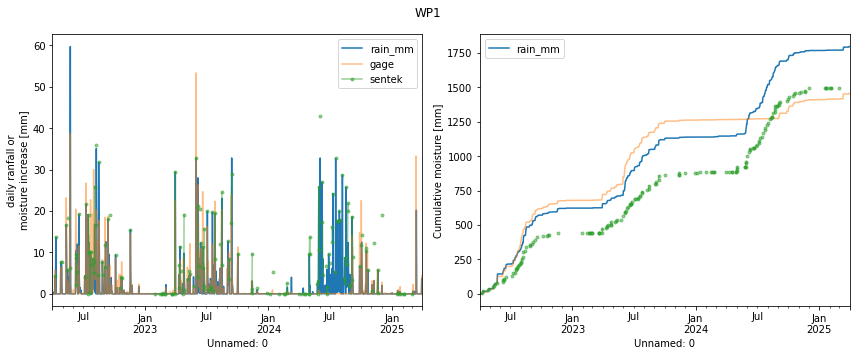

WP1 , interception rate:  16.8 %


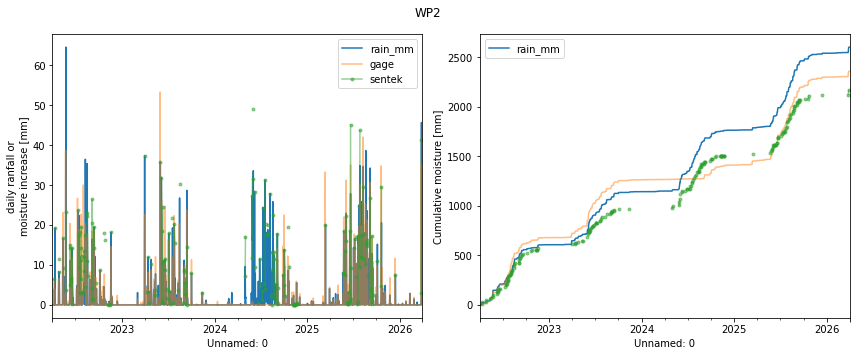

WP2 , interception rate:  16.8 %


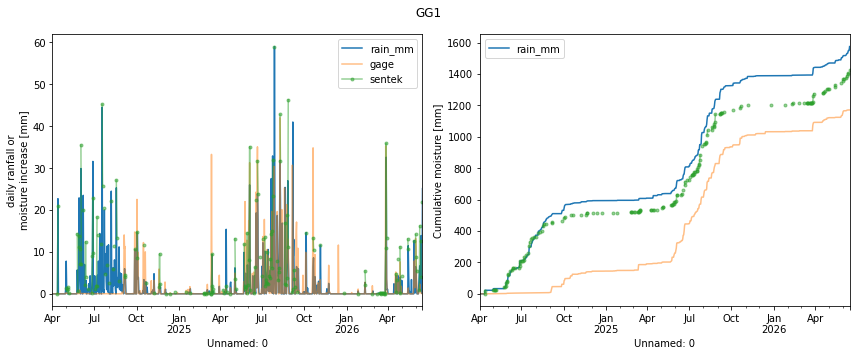

GG1 , interception rate:  9.4 %
GN no weather


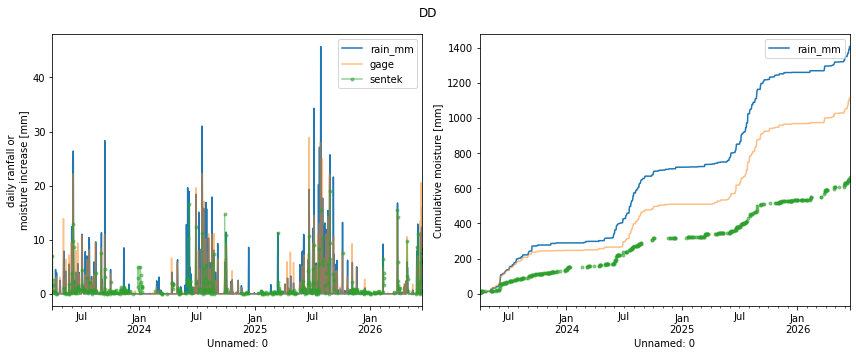

DD , interception rate:  52.8 %


In [912]:
# this block does two things.
# (1) it adds subdaily flags to the subdaily data
# (2) it adds flags to all data for nonphysical moisture increases


wateruse = pd.read_csv('../Data/wateruse10082026.csv').drop(columns='Unnamed: 0')
for site in list(files.keys())[:-4]:
    wsub = wateruse[wateruse.site==site]
    
    sm = pd.read_csv('../Data/final_processed_data/vwc_simoneprocess_driftcorrection_'+site+'.csv')
    processed = pd.read_csv('../Data/final_processed_data/vwc_simoneprocess_'+site+'.csv')
    smD = pd.read_csv('../Data/final_processed_data/vwc_simoneprocess_driftcorrection_'+site+'_daily.csv')
    processedD = pd.read_csv('../Data/final_processed_data/vwc_simoneprocess_'+site+'_daily.csv')
    
    for df in [sm,processed,smD,processedD]:
        df['Date Time'] = pd.to_datetime(df['Date Time'])
        df.set_index('Date Time',inplace=True)
    ds = sm.columns[:-1]
    
    SILO = pd.read_csv('../Data/'+site+'/silo_rainfall_'+site+'.csv',
                      sep=r'\s+',header=None,)
    
    SILO.rename(columns={0:'year',
                    1:'month',
                    2:'day',
                    3:'doy',
                    4:'rain_mm'},inplace=True)
    SILO['datetime'] = pd.to_datetime(SILO.year.astype('str')+'-'+
                                     SILO.month.astype('str')+'-'+
                                     SILO.day.astype('str'))
    SILO = SILO.set_index('datetime')[['rain_mm']]
    
    try:
        weather = pd.read_csv('../Data/final_processed_data/'+site+'_weather.csv')
        weather['Unnamed: 0'] = pd.to_datetime(weather['Unnamed: 0'])
        weather.set_index('Unnamed: 0',inplace=True)
        weather['Trolling'] = weather.air_temperature_C.rolling(48).mean()
        weather['date'] = weather.index.date
    except:
        print(site,'no weather')
        continue
    
    for col in sm.columns[:]:
        if ('flag' not in col)&('Date' not in col):
            for df in [sm,processed]:
                dverify = wsub[wsub.depth==float(col)]
                df[col+'_subdaily_flag'] = np.where(df.index.astype('str').isin(dverify.date.values),
                                               0,-1)
                
#     print(len(weather),len(SILO))
    maxdepth = {'WP1':1.9,'WP2':2.,'GG1':5.,'GN':10, 'DD':7}
    gwdepth = maxdepth[site]*100

    sw = sm.copy()
    # print(gwdepth,sm.columns)
    sw = sw[[c for c in ds if float(c)<gwdepth/100]]
    sw = sw.loc[weather.index.values[0]:weather.index.values[-1]].interpolate()
    ss1 = total_moisture_mm(sw)
    minvs = {'GG1':'4-1-2024',
            'WP1':'4-1-2022',
            'WP2':'4-1-2022',
            'DD':'4-1-2023'}
    maxvs = {'GG1':'6-15-2026',
            'WP1':'4-1-2025',
            'WP2':'4-1-2026',
            'DD':'6-15-2026'}
    minv = pd.to_datetime(minvs[site])
    maxv = pd.to_datetime(maxvs[site])
    fig,axs = plt.subplots(1,2,figsize = (12,5))
    ax = axs[0]
    SILO.loc[minv:maxv].plot(label='SILO',ax=ax)
    weather.rain_mm.loc[minv:maxv].resample('D').sum().plot(label='gage',ax=ax,alpha=.5)
    ss = ss1.sum(axis=1).resample('D').median().diff()
    ss = ss[ss>0].resample('D').first().to_frame()
    sss = ss.merge(SILO,left_index=True,right_index=True)
    threshnum = {'GG1':20,
                'WP1':20,
                'WP2':20,
                'DD':20}
    baddates = sss[(sss[0]>sss.rain_mm.rolling(3).sum()*1.2)&(sss[0]>threshnum[site])].index.values
    sss[0] = np.where((sss[0]>sss.rain_mm.rolling(3).sum()*1.2)&(sss[0]>threshnum[site]),
                      sss.rain_mm.rolling(3).max(),sss[0])
    sss[0].loc[minv:maxv].plot(label = 'sentek',marker='.',
                                                      ax=ax,alpha=.5)
    ax.legend()
    ax.set_ylabel('daily ranfall or\nmoisture increase [mm]')
    fig.suptitle(site)
    # plt.show()

    ax = axs[1]
    SILO.loc[minv:maxv].cumsum().plot(label='SILO',ax=ax)
    weather.rain_mm.loc[minv:maxv].resample('D').sum().cumsum().plot(label='gage',ax=ax,
                                                                    alpha=.5)
    sss[0].loc[minv:maxv].cumsum().plot(label = 'sentek',marker='.',
                                                               ax=ax,alpha=.5)
    # plt.legend()
    ax.set_ylabel('Cumulative moisture [mm]')
    fig.tight_layout()
    plt.show()

    Icheck = sss.loc[minv:maxv].cumsum()
    irate = Icheck[0].ffill().values[-1]/Icheck['rain_mm'].values[-1]
    print(site,', interception rate: ',round(100.-irate*100,1),'%')
    
    fnames = ['vwc_simoneprocess_driftcorrect_',
             'vwc_simoneprocess_',
             'vwc_simoneprocess_driftcorrect_daily_',
             'vwc_simoneprocess_daily_']
    for i,df in enumerate([sm,processed,smD,processedD]):
        # flag days when moisture increases in impossible way
        baddates = [(pd.to_datetime(b).date()) for b in baddates]
        df = df.reset_index()
        df['Quality_flags'] = np.where(df['Date Time'].dt.date.isin(baddates),
                                      3,df.Quality_flags)
        df = df.set_index('Date Time')
        df.to_csv('../Data/final_processed_data/'+fnames[i]+'qflags_'+site+'.csv',float_format = ff)

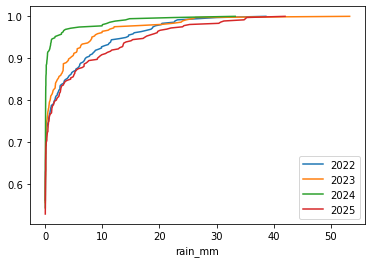

In [882]:
# # this is a CDF figure for WP2. it doesn't run properly, just for me
# weather['wy'] = np.where(weather.index.month>3,
#                         weather.index.year,weather.index.year-1)
# for wy in weather.wy.unique()[1:-1]:
#     wysub = weather[weather.wy==wy]
#     wysub[wysub.rain_mm>0].rain_mm.resample('D').sum().value_counts(normalize=True).sort_index().cumsum().plot(label=wy)
# plt.legend()

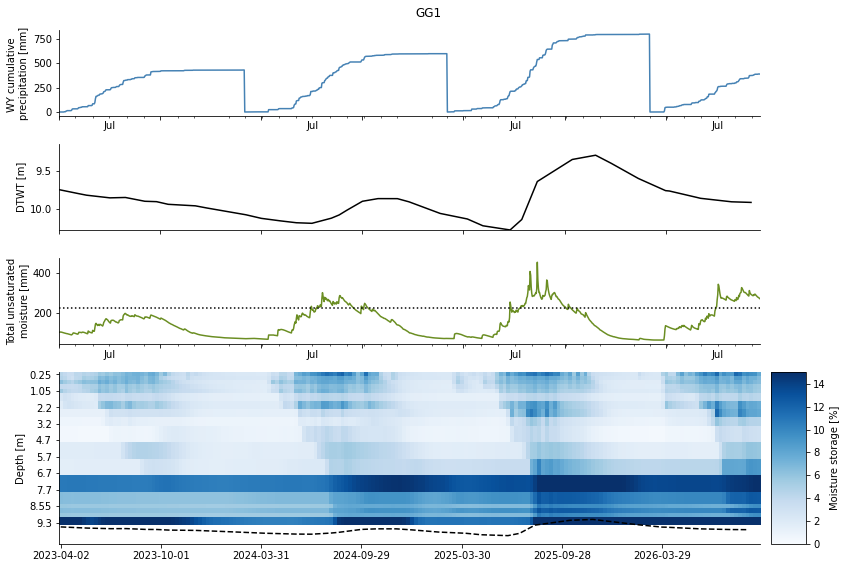

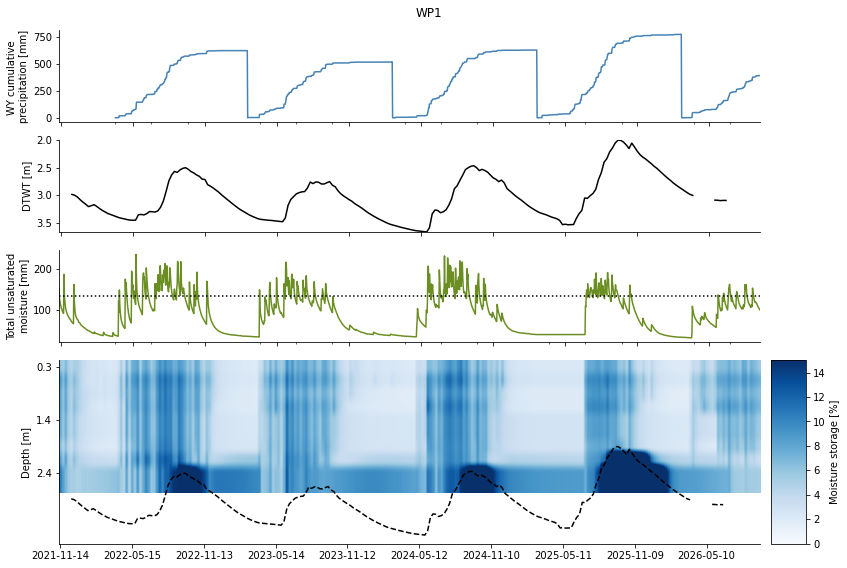

In [925]:
for site in ['GG1','WP1']:#,'WP2','DD']:#list(files.keys())[:-4]:
    sm = pd.read_csv('../Data/final_processed_data/vwc_simoneprocess_driftcorrection_'+site+'_daily.csv')
    sm['Date Time'] = pd.to_datetime(sm['Date Time'])
    sm.set_index('Date Time',inplace=True)
    
    floc = '../Data/final_processed_data/'
    wfile = site+'_weather.csv'
    smfile = floc+'vwc_simoneprocess_driftcorrection_'+site+'_daily.csv'
    if site=='GG1':
        wfile = '../GG1/weather_processed.csv'
    weather = pd.read_csv(floc+'../'+site+'/silo_rainfall_'+site+'.csv',
                          sep=r'\s+',header=None,)
    
    weather.rename(columns={0:'year',
                    1:'month',
                    2:'day',
                    3:'doy',
                    4:'rain_mm'},inplace=True)
    weather['datetime'] = pd.to_datetime(weather.year.astype('str')+'-'+
                                     weather.month.astype('str')+'-'+
                                     weather.day.astype('str'))
    weather = weather.set_index('datetime')[['rain_mm']]
    
    fig,axs = plt.subplots(4,2,figsize = (12,8),#sharex=True,
                          gridspec_kw={'height_ratios':[1,1,1,2],
                                      'width_ratios':[10,.5]},)
    

        
    ax = axs[1,0]

    if site=='GG1':
        gwdata = pd.read_csv('../Data/GG1/GG_manual_groundwater_levels.csv')
        gwdata['measurement_datetime'] = pd.to_datetime(gwdata['measurement_datetime'])
        gwdata.set_index('measurement_datetime',inplace=True)
        gwdata = gwdata['manual_depth_to_water_m_btoc'].dropna()
        gwdata = gwdata.resample('W').mean()
        gwdata = gwdata.interpolate()
        gwdata = gwdata.rename('DTWT')
        gwdata = gwdata.to_frame()
    else:
        gwdata = pd.read_csv('../Data/'+site+'/gwdata_final.csv')
        gwdata['Unnamed: 0'] = pd.to_datetime(gwdata['Unnamed: 0'])
        gwdata.set_index('Unnamed: 0',inplace=True)
        gwdata = gwdata.resample('W').mean()
        if site=='WP1':
            gs0 = gwdata.loc[:'2022-11-12']
            gs1 = (gwdata.loc['2022-11-13':]+(2.32-1.49))
            gwdata = pd.concat([gs0,gs1])
        sitedep = {'WP1':2,
                  'WP2':.5,
                  'DD':1.,}
        gwdata = gwdata.max()-gwdata+sitedep[site]#gwdata.min()
    
    if len(gwdata[~(gwdata.DTWT.isna())])>0:
        ax.plot(gwdata.index,gwdata.DTWT,c='k')
        ax.set_ylim(max(gwdata.DTWT),min(gwdata.DTWT))
        ax.set_ylabel('DTWT [m]')

    ax = axs[2,0]
    sm = sm[sm.Quality_flags.isin([0,2,3])].drop(columns='Quality_flags')
    sm = sm.rename(columns={c:float(c) for c in sm.columns})
    ss = total_moisture_mm(sm)
    
    
    maxdepth = {'WP1':1.9,'WP2':0.9,'GG1':5.,'GN':10, 'DD':1}
    ss = ss[[c for c in ss.columns if float(c)<maxdepth[site]]]
    ss1 = ss.sum(axis=1)
    ss1.plot(ax=ax,c='olivedrab')
    ax.set_ylabel('Total unsaturated\nmoisture [mm]')
    ax.set_xlabel('')
    fillnum = ss1.quantile(.8)
    ax.axhline(fillnum,c='k',ls=':')
    
    ax = axs[0,0]
    weather['wy'] = np.where((weather.index.month<3),weather.index.year-1,
                            weather.index.year)
    weather = weather.loc[sm.index.values[0]:sm.index.values[-1]]
    wsubs = []
    for y in weather.wy.unique():
        wsub = weather[weather.wy==y].rain_mm.cumsum()
        wsubs.append(wsub)
    pd.concat(wsubs).plot(c='steelblue',ax=ax)
    ax.set_ylabel('WY cumulative \nprecipitation [mm]')
    
    ax = axs[3,0]
    curtains1 = sm.resample('W').mean()
    for i in range(1,len(curtains1.columns)):
        diffb = float(curtains1.columns[i])-float(curtains1.columns[i-1])
        if abs(diffb-.2)<0.15:
            continue
        elif abs(diffb-0.5)<0.15:
            curtains1[float(curtains1.columns[i])+.25] = curtains1[curtains1.columns[i]]
        elif abs(diffb-1)<0.15:
            for j in range(3):
                curtains1[float(curtains1.columns[i])+(j+1)*.25] = curtains1[curtains1.columns[i]]
        else:
            print(curtains1.columns[i])
    curtains = curtains1.T
    curtains = curtains.sort_index()
    im = ax.imshow(curtains.values,
             cmap = 'Blues',aspect='auto',vmin = 0,vmax = 15)
    plt.colorbar(im,cax=axs[3,1])
    gwc = curtains1.merge(gwdata.resample('W').mean(),
                left_index=True,right_index=True,how='left')
    color = 'k'
    if site=='WP2':
        color = 'white'
    ax.plot(list(range(len(curtains1))),gwc.DTWT*4-2,
           c=color,ls='--')
    cax = axs[3,1]
    cax.set_ylabel('Moisture storage [%]')
    ax.set_yticks(list(range(0,len(curtains.index),4)))
    ax.set_yticklabels(curtains.index[::4])
    ax.set_ylabel('Depth [m]')
    xlabels = curtains.columns[::26]
    ax.set_xticks(list(range(0,len(curtains.columns),26)))
    ax.set_xticklabels([d.date() for d in xlabels])
        
    for ax in axs:
        ax[0].spines[['top','right']].set_visible(False)
        
        if ax[0]!=axs[3,0]:
            ax[1].axis('off')
            ax[0].set_xticks([d.date() for d in xlabels])
            ax[0].set_xticklabels([])
            ax[0].set_xlabel('')
            ax[0].set_xticklabels('')
            ax[0].set_xlim(sm.index.values[0],sm.index.values[-1])
        
    fig.suptitle(site)
    fig.tight_layout()
    plt.show()